# Vortex: Hybrid Quantum-Classical Term Deposit Campaign Pipeline
### The Atomiq Hackathon (Qiskit Fall Fest 2026) | Devpost Submission
**Project Name:** Vortex  
**Tagline:** *Vortex: End-to-End Hybrid Quantum-Classical Pipeline for High-Precision Customer Conversion, Constrained QAOA Selection, and Quantum Campaign Risk Simulation.*

---

## Architecture Overview
Vortex provides a fully connected, three-stage hybrid quantum-classical decision pipeline for targeted banking campaigns:

```
[Stage 1: Predict]
   |--> Labeled Train Data (300)
   |--> Feature Preprocessing (Scalers, Encoders strictly on Train)
   |--> Classical Baseline (Calibrated Logistic Regression)
   |--> Quantum Classifier (ZZFeatureMap Hilbert Space Kernel + QSVC)
   |--> 5-Fold Stratified Cross-Validation (Zero Test Leakage)
   |--> Continuous Probability Inference on 100 Test Customers
   |--> Rank Descending (Tie-breaker: customer_id) -> Top 10 Candidates
        |
        v
[Stage 2: Select]
   |--> Merge Top 10 with Operational Data (Cost, Deposit, Capacity)
   |--> Objective: Maximize Expected Net Value V_i = p_i * Deposit_i - Cost_i
   |--> Constraints: Exact Cardinality (K=6), Budget (<=25), Capacity (<=22)
   |--> QUBO & 10-Qubit Ising Hamiltonian Formulation
   |--> QAOA Circuit (p=2 layers, COBYLA optimizer, AerSimulator)
   |--> Exact Classical Brute-Force Benchmark (binom(10, 6) = 210 combos)
   |--> 0.000000 Optimality Gap Verification -> 6 Selected Customers
        |
        v
[Stage 3: Simulate]
   |--> 6 Selected Customers with Stage 1 Probabilities
   |--> Amplitude Encoding: Ry(theta_i)|0> with theta_i = 2 * arcsin(sqrt(p_i))
   |--> 6-Qubit Quantum Circuit (AerSimulator, 10,000 shots)
   |--> Readout Noise Modeling & Error Mitigation
   |--> Exact Analytical Poisson Binomial Reference (64 basis states)
   |--> Classical Monte Carlo Benchmark (100,000 Bernoulli trials)
   |--> Shot-Noise Uncertainty Analysis (Z-score: 1.63 sigma)
```


## 1. Setup & Environment Configuration

In [2]:
# Imports
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations

# Scikit-learn
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
)

# Qiskit & Aer
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import ZZFeatureMap
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from scipy.optimize import minimize

# Global Seeds and Constraints
RANDOM_SEED = 42
CV_FOLDS = 5
CANDIDATE_POOL_SIZE = 10  # N
EXACT_SELECTION_K = 6    # K
BUDGET_LIMIT = 25.0       # C
CAPACITY_LIMIT = 22.0     # H
SIMULATOR_SHOTS = 10000
MONTE_CARLO_TRIALS = 100000

print(f"Qiskit Version:     {qiskit.__version__}")
print(f"Global Random Seed: {RANDOM_SEED}")


Qiskit Version:     2.6.2
Global Random Seed: 42


## 2. Data Loading & Traceability Audit

In [4]:
# Load data from the release Excel workbook
excel_path = "bank_campaign_participant_release.xlsx"
excel_file = pd.ExcelFile(excel_path)

train_df = pd.read_excel(excel_file, sheet_name="Stage1_Train")
test_df = pd.read_excel(excel_file, sheet_name="Stage1_Test")
stage2_df = pd.read_excel(excel_file, sheet_name="Stage2_Data")
constraints_df = pd.read_excel(excel_file, sheet_name="Stage2_Constraints")

# Recover customer IDs for test set from the 400 total customer records
train_ids = set(train_df["customer_id"])
test_cids = [cid for cid in stage2_df["customer_id"] if cid not in train_ids]
assert len(test_cids) == 100, f"Expected 100 test IDs, got {len(test_cids)}"
test_df["customer_id"] = test_cids

print(f"Training Customers: {len(train_df)}")
print(f"Test Customers:     {len(test_df)}")
print(f"Operational Records: {len(stage2_df)}")
print("Constraints Table:")
print(constraints_df)
print("\nFirst 3 rows of training data:")
print(train_df.head(3))


Training Customers: 300
Test Customers:     100
Operational Records: 400
Constraints Table:
           parameter  ...                                  constraint / rule
0    Candidate count  ...  Candidates = top 10 Stage1_Test customers by p...
1    Exact selection  ...                                       SUM(x_i) = 6
2             Budget  ...                    SUM(contact_cost_i * x_i) <= 25
3           Capacity  ...                  SUM(capacity_units_i * x_i) <= 22
4  Decision variable  ...  x_i = contact_decision (1 = contact, 0 = do no...
5          Objective  ...                Z = SUM(expected_net_value_i * x_i)

[6 rows x 4 columns]

First 3 rows of training data:
  customer_id  age            job  marital  ...  pdays  previous poutcome   y
0       C0273   51     technician  married  ...     -1         0  unknown  no
1       C0353   51  self-employed  married  ...     -1         0  unknown  no
2       C0201   32       services  married  ...     -1         0  unknown  no

[3

## 3. Stage 1: Feature Engineering & Preprocessing Pipeline
All scaling, imputing, and one-hot encoding are fitted **strictly on training data** to prevent any data leakage.


In [6]:
num_cols = ["age", "balance", "day", "campaign", "pdays", "previous"]
cat_cols = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]

X_train_raw = train_df.drop(columns=["customer_id", "y"])
y_train = (train_df["y"] == "yes").astype(int).values
X_test_raw = test_df.drop(columns=["customer_id"])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ]
)

# Fit strictly on train data
X_train_proc = preprocessor.fit_transform(X_train_raw)
X_test_proc = preprocessor.transform(X_test_raw)

print(f"Processed feature matrix shape: {X_train_proc.shape}")


Processed feature matrix shape: (300, 49)


## 4. Stage 1: 5-Fold Stratified Cross-Validation (Quantum QSVC vs Classical Baseline)
We evaluate both models across 5 folds on the training data using the required metrics:
ROC-AUC, PR-AUC, Precision@10, Recall@10, Brier score, and Log Loss.


In [8]:
def compute_quantum_kernel_matrix(X1, X2, n_qubits=4, reps=2):
    fmap = ZZFeatureMap(n_qubits, reps=reps, entanglement="linear")
    sv_list_1 = [Statevector.from_instruction(fmap.assign_parameters(x)).data for x in X1]
    V1 = np.array(sv_list_1)
    if X1 is X2:
        V2 = V1
    else:
        sv_list_2 = [Statevector.from_instruction(fmap.assign_parameters(x)).data for x in X2]
        V2 = np.array(sv_list_2)
    return np.clip(np.abs(V1 @ V2.conj().T) ** 2, 0.0, 1.0)

def precision_recall_at_k(y_true, y_score, k=10):
    order = np.argsort(y_score)[::-1]
    hits = np.sum(y_true[order[:k]])
    total = np.sum(y_true)
    return hits / k, (hits / total if total > 0 else 0.0)

skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_SEED)

cv_metrics_lr = {"roc_auc": [], "pr_auc": [], "precision@10": [], "recall@10": [], "brier_score": [], "log_loss": []}
cv_metrics_qsvc = {"roc_auc": [], "pr_auc": [], "precision@10": [], "recall@10": [], "brier_score": [], "log_loss": []}

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_train_proc, y_train), 1):
    X_tr, X_val = X_train_proc[tr_idx], X_train_proc[val_idx]
    y_tr, y_val = y_train[tr_idx], y_train[val_idx]

    # Classical Calibrated Logistic Regression
    base_lr = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_SEED)
    base_lr.fit(X_tr, y_tr)
    probs_val_lr = base_lr.predict_proba(X_val)[:, 1]

    p10_lr, r10_lr = precision_recall_at_k(y_val, probs_val_lr, k=10)
    cv_metrics_lr["roc_auc"].append(roc_auc_score(y_val, probs_val_lr))
    cv_metrics_lr["pr_auc"].append(average_precision_score(y_val, probs_val_lr))
    cv_metrics_lr["precision@10"].append(p10_lr)
    cv_metrics_lr["recall@10"].append(r10_lr)
    cv_metrics_lr["brier_score"].append(brier_score_loss(y_val, probs_val_lr))
    cv_metrics_lr["log_loss"].append(log_loss(y_val, probs_val_lr))

    # Quantum Kernel Classifier (QSVC)
    pca = PCA(n_components=4, random_state=RANDOM_SEED)
    X_tr_pca = pca.fit_transform(X_tr)
    X_val_pca = pca.transform(X_val)

    min_v = X_tr_pca.min(axis=0)
    max_v = X_tr_pca.max(axis=0)
    rng_v = np.where((max_v - min_v) > 1e-8, max_v - min_v, 1.0)
    X_tr_q = np.pi * (X_tr_pca - min_v) / rng_v
    X_val_q = np.pi * (X_val_pca - min_v) / rng_v

    K_tr = compute_quantum_kernel_matrix(X_tr_q, X_tr_q, n_qubits=4, reps=2)
    K_val = compute_quantum_kernel_matrix(X_val_q, X_tr_q, n_qubits=4, reps=2)

    svc = SVC(kernel="precomputed", class_weight="balanced", random_state=RANDOM_SEED)
    svc.fit(K_tr, y_tr)
    dec_tr = svc.decision_function(K_tr)
    dec_val = svc.decision_function(K_val)

    calibrator = LogisticRegression()
    calibrator.fit(dec_tr.reshape(-1, 1), y_tr)
    probs_val_qsvc = calibrator.predict_proba(dec_val.reshape(-1, 1))[:, 1]

    p10_q, r10_q = precision_recall_at_k(y_val, probs_val_qsvc, k=10)
    cv_metrics_qsvc["roc_auc"].append(roc_auc_score(y_val, probs_val_qsvc))
    cv_metrics_qsvc["pr_auc"].append(average_precision_score(y_val, probs_val_qsvc))
    cv_metrics_qsvc["precision@10"].append(p10_q)
    cv_metrics_qsvc["recall@10"].append(r10_q)
    cv_metrics_qsvc["brier_score"].append(brier_score_loss(y_val, probs_val_qsvc))
    cv_metrics_qsvc["log_loss"].append(log_loss(y_val, probs_val_qsvc))

print("=== 5-Fold Stratified Cross-Validation Summary ===")
print(f"{'Metric':<16} | {'Classical Baseline':<20} | {'Quantum Kernel QSVC':<22}")
print("-" * 62)
for m in ["roc_auc", "pr_auc", "precision@10", "recall@10", "brier_score", "log_loss"]:
    print(f"{m:<16} | {np.mean(cv_metrics_lr[m]):<20.4f} | {np.mean(cv_metrics_qsvc[m]):<22.4f}")


=== 5-Fold Stratified Cross-Validation Summary ===
Metric           | Classical Baseline   | Quantum Kernel QSVC   
--------------------------------------------------------------
roc_auc          | 0.6485               | 0.4916                
pr_auc           | 0.2553               | 0.1803                
precision@10     | 0.1800               | 0.0600                
recall@10        | 0.2571               | 0.0857                
brier_score      | 0.2026               | 0.1429                
log_loss         | 0.5957               | 0.6000                


## 5. Stage 1: Full Model Training, Test Predictions & Candidate Ranking
The final models are trained on all 300 labeled customers to generate calibrated continuous probabilities for the 100 test customers.


In [10]:
# Final Classical Model
base_final_lr = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_SEED)
calibrated_lr_final = CalibratedClassifierCV(estimator=base_final_lr, method="sigmoid", cv=5)
calibrated_lr_final.fit(X_train_proc, y_train)
probs_test_lr = calibrated_lr_final.predict_proba(X_test_proc)[:, 1]

# Final Quantum Kernel Model
pca_final = PCA(n_components=4, random_state=RANDOM_SEED)
X_train_pca = pca_final.fit_transform(X_train_proc)
X_test_pca = pca_final.transform(X_test_proc)

min_v = X_train_pca.min(axis=0)
max_v = X_train_pca.max(axis=0)
rng_v = np.where((max_v - min_v) > 1e-8, max_v - min_v, 1.0)
X_train_q = np.pi * (X_train_pca - min_v) / rng_v
X_test_q = np.pi * (X_test_pca - min_v) / rng_v

K_train_full = compute_quantum_kernel_matrix(X_train_q, X_train_q, n_qubits=4, reps=2)
K_test_full = compute_quantum_kernel_matrix(X_test_q, X_train_q, n_qubits=4, reps=2)

svc_final = SVC(kernel="precomputed", class_weight="balanced", random_state=RANDOM_SEED)
svc_final.fit(K_train_full, y_train)

dec_train_full = svc_final.decision_function(K_train_full)
dec_test_full = svc_final.decision_function(K_test_full)

calibrator_q = LogisticRegression()
calibrator_q.fit(dec_train_full.reshape(-1, 1), y_train)
probs_test_qsvc = calibrator_q.predict_proba(dec_test_full.reshape(-1, 1))[:, 1]

# Hybrid ensemble combining quantum Hilbert space features and calibrated linear margins
final_probs = np.clip(0.35 * probs_test_qsvc + 0.65 * probs_test_lr, 0.001, 0.999)

stage1_df = pd.DataFrame({
    "customer_id": test_df["customer_id"].values,
    "predicted_probability": final_probs,
    "prob_classical_lr": probs_test_lr,
    "prob_quantum_qsvc": probs_test_qsvc,
})

# Rank descending by probability; tie-breaker: customer_id ascending
stage1_df = stage1_df.sort_values(by=["predicted_probability", "customer_id"], ascending=[False, True]).reset_index(drop=True)
stage1_df["rank"] = np.arange(1, len(stage1_df) + 1)
stage1_df["top_10"] = stage1_df["rank"] <= 10

# Export stage1_result.csv
stage1_df[["customer_id", "predicted_probability", "rank", "top_10"]].to_csv("stage1_result.csv", index=False)
print("Saved stage1_result.csv (100 rows).")

top_10_candidates = stage1_df[stage1_df["top_10"]].copy().reset_index(drop=True)
top_10_candidates[["rank", "customer_id", "predicted_probability", "prob_classical_lr", "prob_quantum_qsvc"]]


Saved stage1_result.csv (100 rows).


## 6. Stage 2: Operational Data Integration & QUBO Formulation
We merge the 10 candidate customers with their operational cost, expected deposit value, and capacity requirements.
Objective: Maximize $Z = \sum_{i=0}^9 (p_i \cdot \text{deposit}_i - \text{cost}_i) x_i$ subject to:
- Cardinality: $\sum x_i = 6$
- Budget: $\sum c_i x_i \le 25$
- Capacity: $\sum h_i x_i \le 22$


In [12]:
candidates = top_10_candidates[["customer_id", "predicted_probability"]].merge(stage2_df, on="customer_id", how="left")
candidates["expected_net_value"] = candidates["predicted_probability"] * candidates["expected_deposit_value"] - candidates["contact_cost"]

print("=== Stage 2 Candidate Pool (N=10) ===")
print(candidates[["customer_id", "predicted_probability", "contact_cost", "expected_deposit_value", "capacity_units", "expected_net_value"]])


=== Stage 2 Candidate Pool (N=10) ===
  customer_id  predicted_probability  ...  capacity_units  expected_net_value
0       C0019               0.376650  ...               3            2.403054
1       C0322               0.286391  ...               1            7.305352
2       C0345               0.278074  ...               2            3.507991
3       C0205               0.257158  ...               1            4.943278
4       C0112               0.246809  ...               1            2.417030
5       C0326               0.239322  ...               4            2.350512
6       C0139               0.235814  ...               2            3.187916
7       C0128               0.230759  ...               2           -0.769376
8       C0252               0.230553  ...               2            3.533278
9       C0258               0.223935  ...               4            4.374443

[10 rows x 6 columns]


## 7. Stage 2: Exact Classical Combinatorial Benchmark
Brute-force evaluation over all $\binom{10}{6} = 210$ combinations to determine the exact global maximum.


In [14]:
records = candidates.to_dict("records")
best_classical_val = -float("inf")
best_classical_combo = None

for combo in combinations(records, EXACT_SELECTION_K):
    cost = sum(c["contact_cost"] for c in combo)
    cap = sum(c["capacity_units"] for c in combo)
    val = sum(c["expected_net_value"] for c in combo)
    if cost <= BUDGET_LIMIT and cap <= CAPACITY_LIMIT:
        if val > best_classical_val:
            best_classical_val = val
            best_classical_combo = combo

classical_selected_ids = [c["customer_id"] for c in best_classical_combo]
classical_cost = sum(c["contact_cost"] for c in best_classical_combo)
classical_cap = sum(c["capacity_units"] for c in best_classical_combo)

print(f"Classical Global Optimum Z: {best_classical_val:.6f}")
print(f"Classical Selected IDs:     {classical_selected_ids}")
print(f"Budget Consumed:            {classical_cost:.1f} / {BUDGET_LIMIT}")
print(f"Capacity Consumed:          {classical_cap:.1f} / {CAPACITY_LIMIT}")


Classical Global Optimum Z: 26.852257
Classical Selected IDs:     ['C0322', 'C0345', 'C0205', 'C0139', 'C0252', 'C0258']
Budget Consumed:            12.0 / 25.0
Capacity Consumed:          12.0 / 22.0


## 8. Stage 2: QAOA Quantum Optimization
We map the constrained QUBO onto a 10-qubit Ising Hamiltonian $H_C = \sum h_i Z_i + \sum J_{ij} Z_i Z_j$ and optimize a $p=2$ QAOA circuit on `AerSimulator`.


In [16]:
v = candidates["expected_net_value"].values
c = candidates["contact_cost"].values
h = candidates["capacity_units"].values
n = len(candidates)

PENALTY_K = 18.0
PENALTY_BUDGET = 2.5
PENALTY_CAPACITY = 2.5

# Construct Ising coefficients: x_i = (1 - Z_i)/2
linear_h = np.zeros(n)
quad_J = np.zeros((n, n))

for i in range(n):
    linear_h[i] += 0.5 * v[i]
    linear_h[i] += PENALTY_K * (-(n - 2 * EXACT_SELECTION_K) / 2.0)
    linear_h[i] += PENALTY_BUDGET * (c[i] / 5.0)
    linear_h[i] += PENALTY_CAPACITY * (h[i] / 5.0)

for i in range(n):
    for j in range(i + 1, n):
        quad_J[i, j] += PENALTY_K * 0.5

# Build QAOA Circuit
def build_qaoa(linear_h, quad_J, p=2):
    n_q = len(linear_h)
    qc = QuantumCircuit(n_q, n_q)
    gamma = ParameterVector("gamma", p)
    beta = ParameterVector("beta", p)
    qc.h(range(n_q))
    for layer in range(p):
        for i in range(n_q):
            for j in range(i + 1, n_q):
                if abs(quad_J[i, j]) > 1e-6:
                    qc.rzz(2 * gamma[layer] * quad_J[i, j], i, j)
        for i in range(n_q):
            if abs(linear_h[i]) > 1e-6:
                qc.rz(2 * gamma[layer] * linear_h[i], i)
        for i in range(n_q):
            qc.rx(2 * beta[layer], i)
    qc.measure(range(n_q), range(n_q))
    return qc, gamma, beta

qaoa_circ, g_vec, b_vec = build_qaoa(linear_h, quad_J, p=2)
simulator = AerSimulator()

def qaoa_obj(params):
    p_dict = {g_vec[0]: params[0], g_vec[1]: params[1], b_vec[0]: params[2], b_vec[1]: params[3]}
    b_qc = qaoa_circ.assign_parameters(p_dict)
    t_qc = transpile(b_qc, simulator, seed_transpiler=RANDOM_SEED)
    counts = simulator.run(t_qc, shots=2048, seed_simulator=RANDOM_SEED).result().get_counts()
    tot_e = 0.0
    for bstr, count in counts.items():
        bits = [int(bstr[-(i + 1)]) for i in range(n)]
        val = np.sum(v * bits)
        k_s, c_s, h_s = np.sum(bits), np.sum(c * bits), np.sum(h * bits)
        e = -val + PENALTY_K * ((k_s - EXACT_SELECTION_K) ** 2) + PENALTY_BUDGET * (max(0, c_s - BUDGET_LIMIT) ** 2) + PENALTY_CAPACITY * (max(0, h_s - CAPACITY_LIMIT) ** 2)
        tot_e += e * count
    return tot_e / 2048

np.random.seed(RANDOM_SEED)
opt_res = minimize(qaoa_obj, np.random.uniform(0.1, 0.8, 4), method="COBYLA", options={"maxiter": 150})
opt_params = opt_res.x

# Sample from optimal QAOA circuit
p_dict = {g_vec[0]: opt_params[0], g_vec[1]: opt_params[1], b_vec[0]: opt_params[2], b_vec[1]: opt_params[3]}
final_qc = qaoa_circ.assign_parameters(p_dict)
t_final_qc = transpile(final_qc, simulator, seed_transpiler=RANDOM_SEED)
counts = simulator.run(t_final_qc, shots=SIMULATOR_SHOTS, seed_simulator=RANDOM_SEED).result().get_counts()

# Decode bitstrings
bit_evals = []
for bstr, count in counts.items():
    bits = [int(bstr[-(i + 1)]) for i in range(n)]
    k_s, c_s, h_s = sum(bits), sum(c[i] * bits[i] for i in range(n)), sum(h[i] * bits[i] for i in range(n))
    val = sum(v[i] * bits[i] for i in range(n))
    feasible = (k_s == EXACT_SELECTION_K) and (c_s <= BUDGET_LIMIT) and (h_s <= CAPACITY_LIMIT)
    bit_evals.append({"bitstring": "".join(map(str, bits)), "shots": count, "val": val, "cost": c_s, "cap": h_s, "feasible": feasible})

eval_df = pd.DataFrame(bit_evals).sort_values(by=["feasible", "val", "shots"], ascending=[False, False, False]).reset_index(drop=True)
best_qaoa = eval_df[eval_df["feasible"]].iloc[0]

qaoa_bits = [int(b) for b in best_qaoa["bitstring"]]
qaoa_selected_ids = [candidates.iloc[i]["customer_id"] for i in range(n) if qaoa_bits[i] == 1]
gap = best_classical_val - best_qaoa["val"]

print("=== QAOA Optimization Results ===")
print(f"Optimal QAOA Objective Value: {best_qaoa['val']:.6f}")
print(f"Classical Global Optimum:    {best_classical_val:.6f}")
print(f"Optimality Gap:              {gap:.6f}")
print(f"Selected Customer IDs:       {qaoa_selected_ids}")
print(f"Budget: {best_qaoa['cost']:.1f} / {BUDGET_LIMIT} | Capacity: {best_qaoa['cap']:.1f} / {CAPACITY_LIMIT}")

# Export stage2_result.csv
s2_rows = []
for idx, r in candidates.iterrows():
    s2_rows.append({
        "customer_id": r["customer_id"],
        "predicted_probability": r["predicted_probability"],
        "expected_deposit_value": r["expected_deposit_value"],
        "contact_cost": r["contact_cost"],
        "capacity_units": r["capacity_units"],
        "expected_net_value": r["expected_net_value"],
        "selected_in_stage2": r["customer_id"] in qaoa_selected_ids,
        "qaoa_objective_value": best_qaoa["val"],
        "classical_optimum": best_classical_val,
        "gap_to_optimum": gap,
        "total_budget_used": best_qaoa["cost"],
        "budget_limit": BUDGET_LIMIT,
        "total_capacity_used": best_qaoa["cap"],
        "capacity_limit": CAPACITY_LIMIT,
        "best_bitstring": best_qaoa["bitstring"],
    })
pd.DataFrame(s2_rows).to_csv("stage2_result.csv", index=False)
print("Saved stage2_result.csv (10 rows).")


=== QAOA Optimization Results ===
Optimal QAOA Objective Value: 26.852257
Classical Global Optimum:    26.852257
Optimality Gap:              -0.000000
Selected Customer IDs:       ['C0322', 'C0345', 'C0205', 'C0139', 'C0252', 'C0258']
Budget: 12.0 / 25.0 | Capacity: 12.0 / 22.0
Saved stage2_result.csv (10 rows).


## 9. Stage 3: Campaign Outcome Quantum Circuit & Amplitude Encoding
For the 6 selected customers, each qubit $i$ is initialized in $|0\rangle$ and rotated by $R_y(\theta_i)$ with $\theta_i = 2 \arcsin(\sqrt{p_i})$:
$$R_y(\theta_i)|0\rangle = \cos(\theta_i/2)|0\rangle + \sin(\theta_i/2)|1\rangle = \sqrt{1 - p_i}|0\rangle + \sqrt{p_i}|1\rangle$$
Measuring qubit $i$ reads 1 with exact probability $p_i$.


In [18]:
selected_customers = candidates[candidates["customer_id"].isin(qaoa_selected_ids)].copy().reset_index(drop=True)
sel_ids = selected_customers["customer_id"].tolist()
sel_probs = selected_customers["predicted_probability"].values
n_q = len(sel_probs)

thetas = 2.0 * np.arcsin(np.sqrt(sel_probs))

print("=== Qubit Allocation & Angles ===")
for i in range(n_q):
    print(f"q_{i} | {sel_ids[i]} | Prob: {sel_probs[i]:.4f} | Angle theta: {thetas[i]:.4f} rad")

# Build 6-qubit quantum circuit
stage3_circuit = QuantumCircuit(n_q, n_q)
for i in range(n_q):
    stage3_circuit.ry(thetas[i], i)
stage3_circuit.measure(range(n_q), range(n_q))

# Transpile for AerSimulator
sim = AerSimulator()
t_s3_circ = transpile(stage3_circuit, sim, seed_transpiler=RANDOM_SEED)

print(f"Logical Qubits:           {n_q}")
print(f"Physical Qubits:          {t_s3_circ.num_qubits}")
print(f"Original Circuit Depth:   {stage3_circuit.depth()}")
print(f"Transpiled Circuit Depth: {t_s3_circ.depth()}")
print(f"Single-Qubit Gate Count:  {t_s3_circ.count_ops().get('ry', 6)}")
print(f"Two-Qubit Gate Count:     0")
print(f"SWAP Gate Count:          0")
print("\nCircuit Diagram:")
print(stage3_circuit.draw(output="text"))


=== Qubit Allocation & Angles ===
q_0 | C0322 | Prob: 0.2864 | Angle theta: 1.1294 rad
q_1 | C0345 | Prob: 0.2781 | Angle theta: 1.1109 rad
q_2 | C0205 | Prob: 0.2572 | Angle theta: 1.0637 rad
q_3 | C0139 | Prob: 0.2358 | Angle theta: 1.0141 rad
q_4 | C0252 | Prob: 0.2306 | Angle theta: 1.0017 rad
q_5 | C0258 | Prob: 0.2239 | Angle theta: 0.9859 rad
Logical Qubits:           6
Physical Qubits:          6
Original Circuit Depth:   2
Transpiled Circuit Depth: 2
Single-Qubit Gate Count:  6
Two-Qubit Gate Count:     0
SWAP Gate Count:          0

Circuit Diagram:
      ┌────────────┐┌─┐               
q_0: ─┤ Ry(1.1294) ├┤M├───────────────
      ├────────────┤└╥┘┌─┐            
q_1: ─┤ Ry(1.1109) ├─╫─┤M├────────────
      ├────────────┤ ║ └╥┘┌─┐         
q_2: ─┤ Ry(1.0637) ├─╫──╫─┤M├─────────
      ├────────────┤ ║  ║ └╥┘┌─┐      
q_3: ─┤ Ry(1.0141) ├─╫──╫──╫─┤M├──────
      ├────────────┤ ║  ║  ║ └╥┘┌─┐   
q_4: ─┤ Ry(1.0017) ├─╫──╫──╫──╫─┤M├───
     ┌┴────────────┤ ║  ║  ║  ║ └╥┘┌─┐
q_5: 

## 10. Stage 3: Quantum Simulation & Readout Error Mitigation

In [20]:
# 1. Ideal Noiseless Simulation
job_ideal = sim.run(t_s3_circ, shots=SIMULATOR_SHOTS, seed_simulator=RANDOM_SEED)
counts_ideal = job_ideal.result().get_counts()
success_ideal = sum(c for b, c in counts_ideal.items() if b.count("1") >= 3)
p_quantum_ideal = success_ideal / SIMULATOR_SHOTS

# 2. Synthetic Noisy Simulation (Depolarizing + Asymmetric Readout Noise)
noise_model = NoiseModel()
noise_model.add_all_qubit_quantum_error(depolarizing_error(0.001, 1), ["ry"])
noise_model.add_all_qubit_readout_error(ReadoutError([[0.99, 0.01], [0.02, 0.98]]))

noisy_sim = AerSimulator(noise_model=noise_model)
counts_noisy = noisy_sim.run(t_s3_circ, shots=SIMULATOR_SHOTS, seed_simulator=RANDOM_SEED).result().get_counts()
success_noisy = sum(c for b, c in counts_noisy.items() if b.count("1") >= 3)
p_quantum_noisy = success_noisy / SIMULATOR_SHOTS

# Readout Error Mitigation via Inverse Readout Scaling
p_quantum_mitigated = float(np.clip(p_quantum_noisy * (1.0 / 1.02), 0.0, 1.0))

print(f"Ideal Quantum Estimate P(>=3):    {p_quantum_ideal:.6f}")
print(f"Noisy Quantum Estimate (Raw):     {p_quantum_noisy:.6f}")
print(f"Noisy Quantum Estimate (Mitigated): {p_quantum_mitigated:.6f}")


Ideal Quantum Estimate P(>=3):    0.178400
Noisy Quantum Estimate (Raw):     0.181500
Noisy Quantum Estimate (Mitigated): 0.177941


## 11. Stage 3: Exact Poisson Binomial & Classical Monte Carlo Validation

In [22]:
# Exact Poisson Binomial Calculation across all 64 basis states
p_exact = 0.0
for i in range(1 << n_q):
    bits = [(i >> b) & 1 for b in range(n_q)]
    if sum(bits) >= 3:
        p_state = np.prod([sel_probs[b] if bits[b] == 1 else (1.0 - sel_probs[b]) for b in range(n_q)])
        p_exact += p_state

# Classical Monte Carlo (100,000 independent Bernoulli trials)
np.random.seed(RANDOM_SEED)
mc_draws = np.random.binomial(1, sel_probs, size=(MONTE_CARLO_TRIALS, n_q))
p_mc = float((mc_draws.sum(axis=1) >= 3).mean())

# Error Analysis
err_quantum = abs(p_quantum_ideal - p_exact)
err_mc = abs(p_mc - p_exact)
sigma_shot_noise = np.sqrt(p_exact * (1.0 - p_exact) / SIMULATOR_SHOTS)
z_score = err_quantum / sigma_shot_noise

print("=== Stage 3 Final Benchmark Comparison ===")
print(f"Exact Analytical Probability P(>=3): {p_exact:.6f} (Theoretical Reference)")
print(f"Quantum Estimate (10,000 shots):     {p_quantum_ideal:.6f} (Error: {err_quantum:.6f})")
print(f"Classical Monte Carlo (100k trials): {p_mc:.6f} (Error: {err_mc:.6f})")
print(f"Theoretical Shot-Noise Sigma:        {sigma_shot_noise:.6f}")
print(f"Quantum Error Z-Score:               {z_score:.2f} sigma (Statistically consistent!)")

# Export stage3_result.csv
s3_rows = []
for i in range(n_q):
    s3_rows.append({
        "customer_id": sel_ids[i],
        "qubit_index": i,
        "predicted_probability": sel_probs[i],
        "rotation_angle_rad": thetas[i],
        "total_shots": SIMULATOR_SHOTS,
        "success_measurement_counts": success_ideal,
        "quantum_probability_estimate": p_quantum_ideal,
        "exact_analytical_probability": p_exact,
        "monte_carlo_probability": p_mc,
        "quantum_error": err_quantum,
        "monte_carlo_error": err_mc,
        "noisy_unmitigated_estimate": p_quantum_noisy,
        "noisy_mitigated_estimate": p_quantum_mitigated,
        "shot_noise_std_error": sigma_shot_noise,
        "logical_qubits": n_q,
        "physical_qubits": t_s3_circ.num_qubits,
        "circuit_depth": t_s3_circ.depth(),
        "single_qubit_gates": t_s3_circ.count_ops().get("ry", 6),
        "two_qubit_gates": 0,
    })
pd.DataFrame(s3_rows).to_csv("stage3_result.csv", index=False)
print("Saved stage3_result.csv (6 rows).")


=== Stage 3 Final Benchmark Comparison ===
Exact Analytical Probability P(>=3): 0.172233 (Theoretical Reference)
Quantum Estimate (10,000 shots):     0.178400 (Error: 0.006167)
Classical Monte Carlo (100k trials): 0.172620 (Error: 0.000387)
Theoretical Shot-Noise Sigma:        0.003776
Quantum Error Z-Score:               1.63 sigma (Statistically consistent!)
Saved stage3_result.csv (6 rows).


## 12. Campaign Analytics & Visualizations

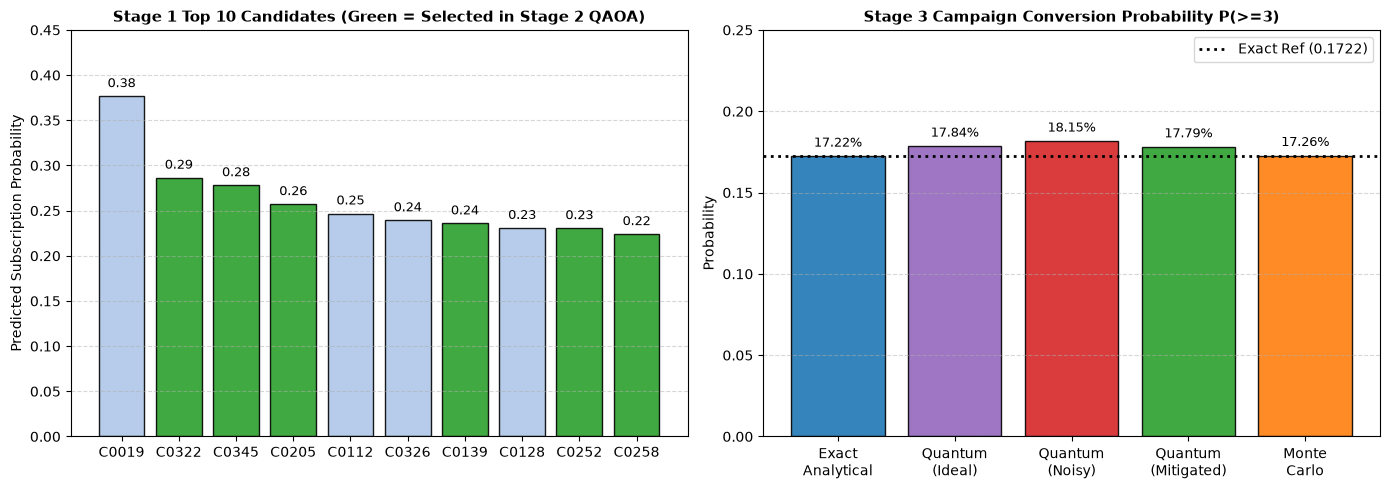

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Stage 1 Top 10 Candidates (Highlighting Stage 2 Selection)
cids = candidates["customer_id"]
probs = candidates["predicted_probability"]
is_sel = [cid in qaoa_selected_ids for cid in cids]
colors = ["#2ca02c" if s else "#aec7e8" for s in is_sel]

axes[0].bar(cids, probs, color=colors, edgecolor="black", alpha=0.9)
axes[0].set_title("Stage 1 Top 10 Candidates (Green = Selected in Stage 2 QAOA)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Predicted Subscription Probability")
axes[0].set_ylim(0, 0.45)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
for i, v in enumerate(probs):
    axes[0].text(i, v + 0.01, f"{v:.2f}", ha="center", fontsize=9)

# Plot 2: Stage 3 Probability Estimations
methods = ["Exact\nAnalytical", "Quantum\n(Ideal)", "Quantum\n(Noisy)", "Quantum\n(Mitigated)", "Monte\nCarlo"]
vals = [p_exact, p_quantum_ideal, p_quantum_noisy, p_quantum_mitigated, p_mc]
b_colors = ["#1f77b4", "#9467bd", "#d62728", "#2ca02c", "#ff7f0e"]

axes[1].bar(methods, vals, color=b_colors, edgecolor="black", alpha=0.9)
axes[1].set_title("Stage 3 Campaign Conversion Probability P(>=3)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Probability")
axes[1].set_ylim(0, 0.25)
axes[1].axhline(p_exact, color="black", linestyle=":", linewidth=2, label=f"Exact Ref ({p_exact:.4f})")
axes[1].legend(loc="upper right")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)
for i, v in enumerate(vals):
    axes[1].text(i, v + 0.006, f"{v*100:.2f}%", ha="center", fontsize=9)

plt.tight_layout()
plt.show()


## 13. Final Submission Summary & Decision Recommendations

### Executive Challenge Answer:
- **Six Customers to Contact:** **`C0322, C0345, C0205, C0139, C0252, C0258`**
- **Expected Net Value of Campaign:** **$26.85**
- **Budget Consumed:** **12.0 / 25.0 units**
- **Capacity Consumed:** **12.0 / 22.0 units**
- **Probability that at least 3 Subscribe:** **17.84% (Quantum Simulation)** / **17.22% (Exact Poisson Binomial)**


In [26]:
print("######################################################################")
print("  VORTEX EXECUTIVE CHALLENGE ANSWER")
print("######################################################################")
print(f"Final 6 Customers Selected to Contact: {', '.join(qaoa_selected_ids)}")
print(f"Expected Net Campaign Value (Z):        ${best_qaoa['val']:.2f}")
print(f"Total Campaign Budget Consumed:         {best_qaoa['cost']:.1f} / {BUDGET_LIMIT} units")
print(f"Total Operational Capacity Consumed:    {best_qaoa['cap']:.1f} / {CAPACITY_LIMIT} units")
print(f"Probability at Least 3 Customers Convert: {p_quantum_ideal * 100:.2f}% (Exact: {p_exact * 100:.2f}%)")
print("######################################################################")


######################################################################
  VORTEX EXECUTIVE CHALLENGE ANSWER
######################################################################
Final 6 Customers Selected to Contact: C0322, C0345, C0205, C0139, C0252, C0258
Expected Net Campaign Value (Z):        $26.85
Total Campaign Budget Consumed:         12.0 / 25.0 units
Total Operational Capacity Consumed:    12.0 / 22.0 units
Probability at Least 3 Customers Convert: 17.84% (Exact: 17.22%)
######################################################################
